# Matching objectives before comparing methods

Level 3. Prerequisites: scalar prices and the control-integrity lesson. Reading time: 40 minutes.

**Question:** Which published solvers agree when given the same elastic or pure L1 objective, and what changes when the chosen penalty family is incompatible?


## Objectives

A solver comparison starts with a mathematical contract. Equal matrices and bounds are insufficient if one method prices violations quadratically and another uses a linear restoration cost. Those are different decisions even when both libraries call them soft constraints. We will therefore use two separately labeled families and compare methods only within each one. A family change will never be interpreted as an improvement in numerical accuracy.

The published generalized projection and DAQP paths cover a symmetric elastic sparse instance. The asymmetric projection, fixed-parameter FlexQP reconstruction and published ElastiQP backend cover a pure L1 instance with unequal side prices. Independent stock-OSQP lifting checks each family. The purpose is to understand objective agreement, representation size and exact-penalty meaning, not to transfer a paper's reported speedup to our machine.


## Setup

Use a separate Python 3.12 environment. The native engine is a separate distribution. Install the exact environment outside the notebook:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

The single setup cell resolves the repository, imports the methods and prints numerical versions. No installation runs inside a kernel.


In [1]:
# Resolve inputs once so every scientific cell focuses on the optimization.
from pathlib import Path
import sys
import json
import importlib.metadata
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
from softqp.flex import solve_flex
from softqp.elasti import solve_elastiqp
from softqp.sessions import PreparedSolver
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
from pipeline.softqp_campaign import generated_problem, primary_endpoint
from pipeline.optimality import kkt
from pipeline.control import predict_states
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Data

We use the product generator with development seed 1000, 32 original variables, 64 rows, row density 0.1 and unit diagonal condition. Rows are normalized to unit Euclidean length. The symmetric elastic family retains its declared hard-row mask. The L1 family explicitly has all rows soft and no quadratic side price, so it is a different authored policy with the same generator settings, not a clandestine relaxation of the first problem.

These inputs are teaching cases. They do not consume a held-out seed or tune any registered numerical setting. The scalar upper-price sweep later isolates the exact-penalty threshold in one dimension.


## Method

For symmetric elastic penalties, the published generalized slack projection changes the interval proximal operation while retaining the principal QP dimensions. An ordinary lift introduces auxiliary variables to express the same cost as a standard QP. DAQP instead solves a dual active-set problem and has its own reciprocal quadratic-weight convention. These algorithmic differences should leave the optimum unchanged when the original convex objective and hard policy match.

Run the authors' pinned generalized-projection implementation first. Its symmetric/unconditional assumptions are satisfied here. The asymmetric extension is unnecessary for this first instance, and replacing its side prices would obscure the question. We print actual dimensions and the original objective rather than comparing internal objective conventions.


In [2]:
# This family satisfies the published symmetric penalty assumptions.
spec = dict(n=32, density=0.1, seed=1000, family="symmetric-elastic", condition=1)
elastic = generated_problem(spec)
settings = dict(eps_abs=1e-8, eps_rel=1e-8, max_iter=200000)
native_settings = dict(settings, adaptive_rho_interval=25)
generalized = solve(elastic, "generalized", **native_settings)
print("Generalized:", generalized["dimensions"])
print(f"Elastic objective: {generalized['metrics']['objective']:.8f}")


Generalized: {'variables': 32, 'rows': 64, 'nnz': 239}
Elastic objective: -44.95315486


The active-set reference receives identical original coefficients. Its positivity requirements are satisfied by the diagonal Hessian and positive elastic quadratic weights. Unsupported conditions would require an incompatible result, not a regularizer inserted into the objective. Retaining this distinction is especially important when a semidefinite Hessian or a pure L1 side is encountered in another case.


In [3]:
# DAQP joins only because both positive-definiteness and elastic costs match.
daqp = solve(elastic, "daqp", **native_settings)
print("DAQP:", daqp["status"], daqp["dimensions"])
print(f"Active-set elastic objective: {daqp['metrics']['objective']:.8f}")


DAQP: soft optimal {'variables': 32, 'rows': 64, 'nnz': 239}
Active-set elastic objective: -44.95315485


Use independent stock lifting to close the first numerical comparison. A small original-space objective difference supports equivalence on this input. It does not prove equivalence for every penalty family, and variable counts are not a timing measurement. In particular, a lower-dimensional factorization can be offset by input validation, iteration behavior or a different implementation language.


In [4]:
# Evaluate a separately formulated QP before comparing dimensions.
elastic_lift = solve(elastic, "lifted", **native_settings)
elastic_results = [elastic_lift, generalized, daqp]
for result in elastic_results:
    difference = abs(result["metrics"]["objective"] - elastic_lift["metrics"]["objective"])
    print(result["method"], f"objective gap {difference:.3e}", result["dimensions"]["variables"])


lifted objective gap 0.000e+00 84
generalized objective gap 1.310e-08 32
daqp objective gap 1.319e-10 32


## Comparison

We now declare a pure L1 problem rather than pretending that the elastic objective fits every library. A weighted hinge is equivalent to a bounded inequality dual. FlexQP implements a fixed-parameter splitting with projection and shrinkage; ElastiQP uses its published dual active-set backend. The generalized symmetric path cannot represent these unequal side prices, and the present DAQP adapter requires positive quadratic prices. Those restrictions belong in the comparison, even though the compatible methods solve the same L1 objective.


In [5]:
# Changing the family is an explicit model decision, not an algorithmic correction.
l1 = generated_problem(dict(spec, family="asymmetric-l1"))
asymmetric_l1 = solve(l1, "asymmetric", **native_settings)
print(f"Asymmetric L1 objective: {asymmetric_l1['metrics']['objective']:.8f}")


Asymmetric L1 objective: -60.96202015


FlexQP here is an independent reconstruction of the paper's fixed equations and Algorithm 1, using sigma_x=1e-6, sigma_s=1, rho=1 and alpha=1.6. Its proximal terms stabilize subproblems without adding a quadratic scientific cost. The learned Deep FlexQP policy is absent because trained reproducibility assets were unavailable. Neither code ownership nor a paper timing result is attributed to this reconstruction.


In [6]:
# Execute the paper-equation reference on exactly the same L1 input.
flex = solve_flex(l1, **settings)
print("FlexQP:", flex["status"], flex["dimensions"])
print(f"FlexQP L1 objective: {flex['metrics']['objective']:.8f}")


FlexQP: solved {'variables': 288, 'rows': 256, 'nnz': 1116}
FlexQP L1 objective: -60.96201997


ElastiQP receives the same finite-side expansion and vector prices, with positive definite P and zero proximal objective regularization in this adapter. A hard inequality would be refused, whereas a supported hard equality would use its distinct equality interface. The exported settings make that boundary inspectable instead of silently turning every row into an elastic inequality.


In [7]:
# Published ElastiQP is a separate implementation from the FlexQP reconstruction.
elasti = solve_elastiqp(l1, **settings)
l1_lift = solve(l1, "lifted", **native_settings)
l1_results = [l1_lift, asymmetric_l1, flex, elasti]
for result in l1_results:
    gap = abs(result["metrics"]["objective"] - l1_lift["metrics"]["objective"])
    diagnostic = kkt(l1, result["x"], result["y"])
    print(result["method"], f"L1 gap {gap:.3e}",
          f"proximal defect {diagnostic['normalized_proximal_defect']:.3e}")


lifted L1 gap 0.000e+00 proximal defect 7.370e-09
asymmetric L1 gap 3.780e-08 proximal defect 3.870e-10
flex L1 gap 1.421e-07 proximal defect 4.678e-08
elastiqp L1 gap 3.833e-08 proximal defect 4.441e-16


Show the actual primal dimensions of each formulation in separate family panels. Auxiliary-variable counts describe mathematical representation. The FlexQP Schur factor dimension is smaller than its full split formulation, so its reported full variable count must not be read as the size of a single dense factor. Likewise, native projection size alone does not establish faster end-to-end execution.


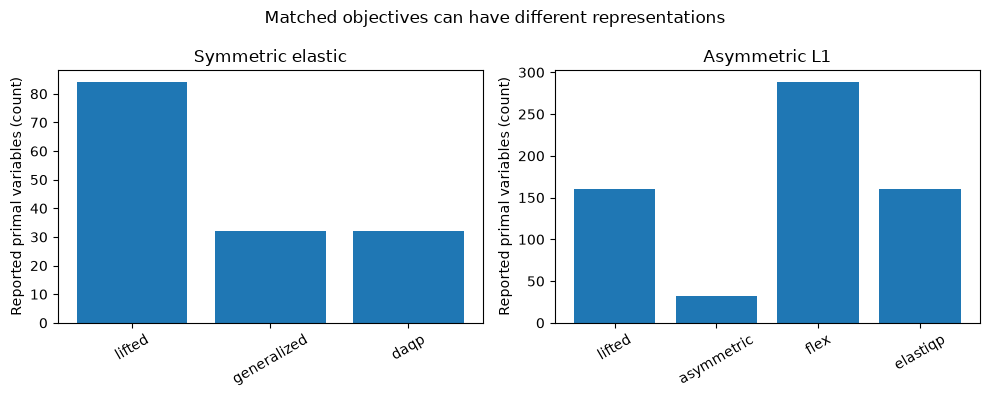

In [8]:
# Compare representation within a family, never objective values between families.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, results, title in zip(axes, [elastic_results, l1_results], ["Symmetric elastic", "Asymmetric L1"]):
    labels = [r["method"] for r in results]
    ax.bar(labels, [r["dimensions"]["variables"] for r in results])
    ax.set(title=title, ylabel="Reported primal variables (count)")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Matched objectives can have different representations")
fig.tight_layout()
plt.show()


The panels expose formulation differences after numerical agreement has been checked, rather than treating the shortest bar as a winner. Some references use finite-side slacks, while generalized projection works in the original QP dimension. Dense active-set internals and a Schur reduction do not follow directly from the displayed variable counts. The plot therefore supports a representation claim only; the registered paired campaign supplies the separate evidence needed for a computational claim.


Finally isolate exact-penalty behavior in the scalar upper case. The hard optimum is the upper boundary x=1 and its hard inequality multiplier is 2 under unit curvature and target 3. A linear weight at least that multiplier can recover the hard optimum; smaller weights intentionally purchase violation. We vary only the upper linear price and run three L1 implementations at every value.


In [9]:
# The exact-penalty threshold depends on this problem's multiplier, not a universal magic weight.
weights = np.array([0.2, 0.5, 1.2, 3.0, 6.0])
curves = {"asymmetric": [], "flex": [], "elastiqp": []}
for weight in weights:
    source = scalar(3.0, asymmetric=True)
    penalty = replace(source.penalty, upper_linear=np.array([weight]),
                      lower_quadratic=np.zeros(1), upper_quadratic=np.zeros(1))
    priced = replace(source, penalty=penalty)
    curves["asymmetric"].append(solve(priced, "asymmetric", **native_settings)["x"][0])
    curves["flex"].append(solve_flex(priced, **settings)["x"][0])
    curves["elastiqp"].append(solve_elastiqp(priced, **settings)["x"][0])
print(f"Decision at upper price 1.2: {curves['asymmetric'][2]:.6f}")


Decision at upper price 1.2: 1.800000


Plot the shared decision against price to separate solver agreement from policy behavior. Overlapping curves support the same L1 optimum within numerical tolerance. The flat segment at the hard optimum appears only after the problem-specific threshold. This example also explains why an always-solvable elastic formulation need not satisfy the original hard inequality when a practitioner deliberately chooses a low price.


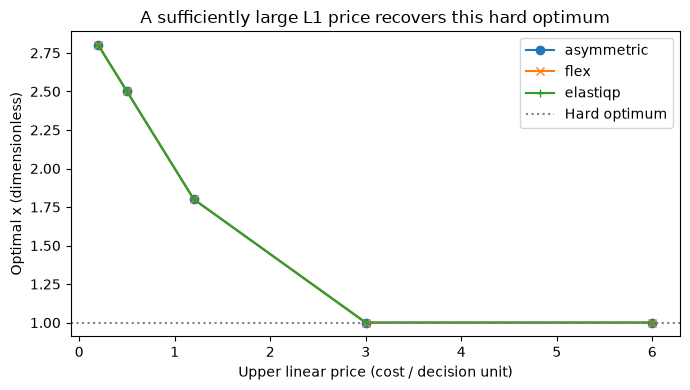

In [10]:
# Offset marker shapes reveal agreement without mixing units or objectives.
fig, ax = plt.subplots(figsize=(7, 4))
for (name, values), marker in zip(curves.items(), ["o", "x", "+"]):
    ax.plot(weights, values, marker=marker, label=name)
ax.axhline(1.0, color="gray", linestyle=":", label="Hard optimum")
ax.set(xlabel="Upper linear price (cost / decision unit)", ylabel="Optimal x (dimensionless)",
       title="A sufficiently large L1 price recovers this hard optimum")
ax.legend()
fig.tight_layout()
plt.show()


At low prices, all three methods prefer a point outside the desired interval. At sufficiently high prices, they reach its upper boundary. Their agreement does not make the low-price solution a hard-feasible solution, nor does the high-price segment prove a universal penalty constant for other QPs. Coupling, objective curvature and row scaling change optimal multipliers. The result is an exact-penalty lesson on a stated scalar problem, not a certification of a learned policy.


## Results

**Answer:** At upper linear price 1.2, the scalar pure L1 optimum is 1.800000, rather than the elastic example's 1.160000. That change is a different objective. Within each sparse family, the printed original-space gaps and proximal diagnostics quantify agreement between the compatible published paths and their independent lift. The plots distinguish representation size from solution policy, and neither supplies a timing ranking.

Deep FlexQP remains a documented unavailable comparator. A learned-policy result has not been fabricated, and the fixed-parameter reconstruction is not labeled as a reproduction of its trained acceleration.


## Summary

First match the objective, finite sides, hard policy and original units; then interpret each backend's status and recover its dual signs. Preserve incompatible cases in the record. Only after those checks is a common computational protocol meaningful. The next lesson tests such a protocol's candidate claim, including the possibility that correct mathematics and smaller matrices still fail to produce a useful time reduction.


## References

- [Generalized slack projections](https://arxiv.org/abs/2610.35631).
- [DAQP original-scale soft weights](https://darnstrom.github.io/daqp/start/advanced/soft).
- [Oshin et al., FlexQP equations and Algorithm 1](https://arxiv.org/html/2512.01565v2).
- [Published ElastiQP implementation](https://github.com/StanfordASL/elastiqp).
